C:\Users\jeztr\AppData\Local\Temp\ipykernel_14228\2366880576.py:46: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm = np.trapz(wavefunctions[:, i] ** 2, x)


Computed Energy Eigenvalues:
E_0 = 1.97058
E_1 = 2.01240
E_2 = 4.90804
E_3 = 5.77363
E_4 = 7.83126
E_5 = 9.94965

Tunneling Splitting (E_1 - E_0): 4.18221e-02 (indicates strong barrier coupling)


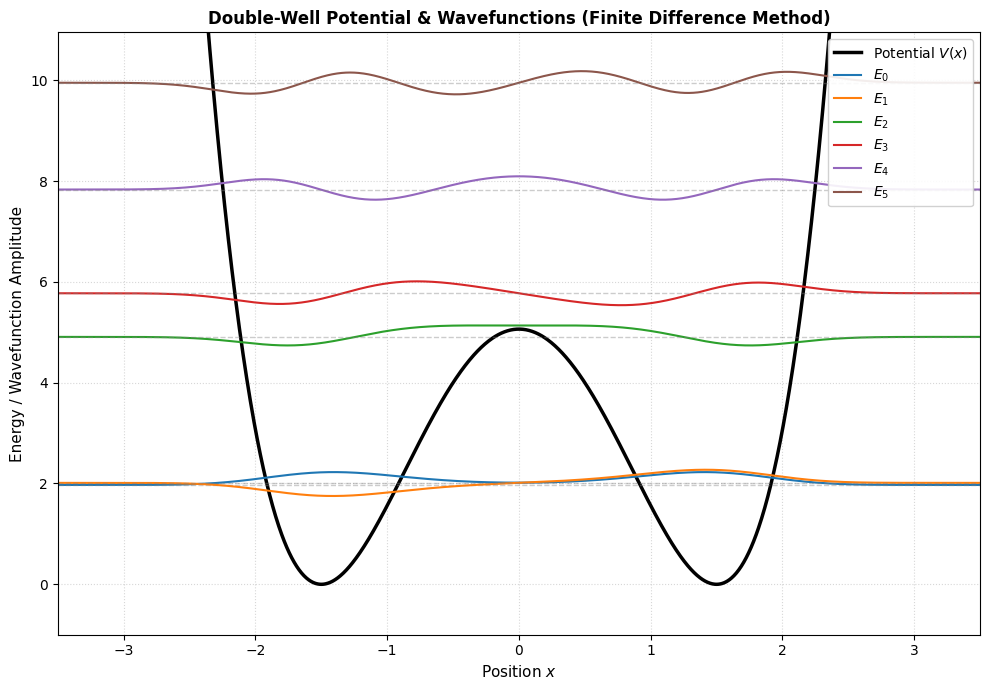

In [6]:

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import eigh

# ==========================================
# 1. PARAMETERS & SPATIAL GRID SETUP
# ==========================================
hbar = 1.0  # Reduced Planck's constant (natural units)
m = 1.0  # Particle mass

N = 1500  # Number of spatial grid points
x_min, x_max = -3.5, 3.5
x = np.linspace(x_min, x_max, N)
dx = x[1] - x[0]  # Grid spacing

# ==========================================
# 2. DEFINE POTENTIAL V(x)
# ==========================================
# Symmetric quartic double-well: V(x) = (x^2 - a^2)^2
a = 1.5  # Controls well separation and barrier height
V = (x**2 - a**2) ** 2

# ==========================================
# 3. CONSTRUCT HAMILTONIAN MATRIX
# ==========================================
# Kinetic energy operator prefactor: -hbar^2 / (2 * m * dx^2)
kinetic_coef = -1.0 * hbar**2 / (2.0 * m * dx**2)

# Main diagonal: -2 * kinetic_coef + V(x_i)
main_diag = -2.0 * kinetic_coef + V

# Off-diagonal elements (nearest-neighbor coupling)
off_diag = np.ones(N - 1) * kinetic_coef

# Assemble the tridiagonal Hamiltonian matrix (Dense format for simplicity)
H = np.diag(main_diag) + np.diag(off_diag, k=1) + np.diag(off_diag, k=-1)

# ==========================================
# 4. SOLVE EIGENVALUE PROBLEM
# ==========================================
num_states = 6  # Number of low-lying eigenstates to compute
energies, wavefunctions = eigh(H, subset_by_index=[0, num_states - 1])

# Normalize wavefunctions such that \int |\psi(x)|^2 dx = 1
for i in range(num_states):
  norm = np.trapz(wavefunctions[:, i] ** 2, x)
  wavefunctions[:, i] /= np.sqrt(norm)

# ==========================================
# 5. PRINT ENERGIES & TUNNELING SPLITTING
# ==========================================
print('Computed Energy Eigenvalues:')
for i, e in enumerate(energies):
  print(f'E_{i} = {e:.5f}')

# Highlight tunneling splitting between ground and first excited states
splitting = energies[1] - energies[0]
print(
    f'\nTunneling Splitting (E_1 - E_0): {splitting:.5e} (indicates strong'
    ' barrier coupling)'
)

# ==========================================
# 6. PLOT RESULTS
# ==========================================
plt.figure(figsize=(10, 7))

# Plot the potential energy curve (scaled down slightly for visual clarity in plot)
plt.plot(x, V, 'k-', linewidth=2.5, label='Potential $V(x)$')

# Plot each wavefunction offset by its respective energy level
scaling_factor = 0.35  # Amplitude scaling for visual display
for i in range(num_states):
  # Offset the wavefunction graph vertically to match its energy eigenvalue
  y_offset = energies[i]
  plt.plot(x, y_offset + wavefunctions[:, i] * scaling_factor, label=f'$E_{i}$')
  plt.axhline(y=energies[i], color='gray', linestyle='--', alpha=0.4, linewidth=1)

plt.title(
    'Double-Well Potential & Wavefunctions (Finite Difference Method)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Position $x$', fontsize=11)
plt.ylabel('Energy / Wavefunction Amplitude', fontsize=11)
plt.xlim(x_min, x_max)
plt.ylim(-1, energies[-1] + 1)
plt.legend(loc='upper right', framealpha=0.9)
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

 
